# 1.Wczytanie bilbiotek

In [ ]:
from pathlib import Path
import time
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# 2.Wczytanie Danych

In [36]:
DATA_DIR = Path("data/zadanie-1") 
DATA_DIR.mkdir(parents=True, exist_ok=True)
archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")
print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")
plik1 = DATA_DIR / "pendigits" / "pendigits.tra"
plik2 = DATA_DIR / "pendigits"/"pendigits.tes"
df_train = pd.read_csv(plik1,header=None)
df_test = pd.read_csv(plik2,header=None)
print("--- plik1 (zbiór treningowy) ---")
display(df_train.head())
print("--- plik2 (zbiór testowy) ---")
display(df_test.head())

Couldn't access the Hub to check for update but local file already exists. Defaulting to existing file. (error: [Errno -3] Temporary failure in name resolution)


Dane zapisano w: data/zadanie-1/pendigits
--- plik1 (zbiór treningowy) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


--- plik2 (zbiór testowy) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,88,92,2,99,16,66,94,37,70,0,0,24,42,65,100,100,8
1,80,100,18,98,60,66,100,29,42,0,0,23,42,61,56,98,8
2,0,94,9,57,20,19,7,0,20,36,70,68,100,100,18,92,8
3,95,82,71,100,27,77,77,73,100,80,93,42,56,13,0,0,9
4,68,100,6,88,47,75,87,82,85,56,100,29,75,6,0,0,9


Wczytujemy dane za pomocą biblioteki pathlib, a następnie rozdzielamy dane treningowe oraz testowe kolejno do plik1 i plik2. Używając biblioteki pandas, możemy zobaczyć zawartość pliku — wypisanych jest pierwsze $5$ wierszy. Kolumny od $0$ do $15$ zawierają współrzędne położenia pióra, natomiast kolumna $16$ przedstawia, jaka cyfra została napisana.

# 3.Sprawdzenie danych

In [37]:
print("--- plik1 (zbiór treningowy) ---")
print(f"liczba pustych lini: {df_train.isnull().sum().sum()}")
print(f"liczba zduplikowanych lini: {df_train.duplicated().sum()}")
print("opis danych")
display(df_train.describe())

print("--- plik2 (zbiór testowy) ---")
print(f"liczba pustych lini: {df_test.isnull().sum().sum()}")
print(f"liczba zduplikowanych lini: {df_test.duplicated().sum()}")
print("opis danych")
display(df_test.describe())


--- plik1 (zbiór treningowy) ---
liczba pustych lini: 0
liczba zduplikowanych lini: 0
opis danych


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000,7494.000000
mean,37.384307,84.679343,40.005604,82.889512,50.878303,65.044436,51.471844,44.599680,57.129971,34.069122,61.417401,35.782092,54.699760,35.800774,46.813718,28.565386,4.430878
std,33.322024,16.848420,26.256025,19.638582,34.927201,27.377341,30.680075,30.659478,33.680340,27.459989,37.130762,27.495836,22.599781,33.223611,41.531794,35.811094,2.876981
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,76.000000,20.000000,70.000000,17.000000,48.000000,28.000000,22.000000,30.000000,7.000000,25.000000,12.000000,41.000000,7.000000,0.000000,0.000000,2.000000
50%,31.000000,89.000000,39.000000,89.000000,56.000000,71.000000,54.000000,42.000000,60.000000,33.000000,74.000000,32.000000,53.000000,28.000000,39.000000,8.000000,4.000000
75%,61.000000,100.000000,58.000000,100.000000,81.000000,86.000000,75.000000,65.000000,88.000000,55.000000,98.000000,57.000000,69.000000,48.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


--- plik2 (zbiór testowy) ---
liczba pustych lini: 0
liczba zduplikowanych lini: 0
opis danych


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
count,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000,3498.000000
mean,41.877930,86.064894,41.891081,85.669525,47.396798,66.705832,50.681246,44.283305,56.308462,32.896512,58.586049,32.779302,55.713265,33.086621,48.302459,29.445111,4.433105
std,35.995293,14.737085,26.486364,17.960876,32.134722,26.130413,30.351970,28.227548,35.089176,26.785929,37.555535,26.183399,21.745726,32.937557,42.234080,35.705016,2.877285
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.000000,77.000000,22.000000,75.000000,19.000000,52.000000,29.000000,26.000000,26.000000,6.000000,21.000000,11.000000,43.000000,4.000000,0.000000,0.000000,2.000000
50%,34.000000,90.000000,42.000000,94.000000,49.000000,71.000000,52.000000,44.000000,59.000000,32.000000,70.000000,28.000000,53.000000,25.000000,42.000000,12.000000,4.000000
75%,75.000000,100.000000,60.000000,100.000000,73.000000,87.000000,73.000000,63.000000,91.000000,52.000000,94.000000,52.000000,68.000000,47.000000,100.000000,51.000000,7.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,9.000000


Używamy biblioteki `pandas` oraz `IPython.display` do sprawdzenia danych w tabeli i wypisania wyników. uzywamy funkcji `isnull` oraz `duplicated` żeby kolejno sprawdzić czy jakaś kolumna posiada puste pola oraz czy psoiada duplikaty. Mozemy zuwazyc w obu przypadkach tabele nie maja duplikatow i pustych kolumn.


# 4. Przygotowanie klasyfikatorów

In [ ]:
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Random Forest": Pipeline([
        ("scaler",StandardScaler()),
        ("clf",RandomForestClassifier())
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)) 
    ])
}

Używamy słownika do zdefiniowania naszych klasyfikatorów — każdy klucz ma swoją wartość. Jako wartość stosujemy obiekt Pipeline, który przepuszcza dane kolejno przez scaler oraz nasz klasyfikator. StandardScaler przekształca każdą kolumnę z danymi tak, aby średnia wynosiła $0$, a odchylenie standardowe $1$. Używamy wzoru:
\begin{aligned}
z &= \frac{x - \mu}{\sigma} \\[12pt]
\mu &= \frac{1}{N} \sum_{i=1}^{N} x_i \\[12pt]
\sigma &= \sqrt{\frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2}
\end{aligned}
$$ 

Dla każdej wartości x z kolumny liczymy z. Używając tego wzoru, skalujemy dane do małego przedziału oraz je centrujemy – tak, aby wartości równe średniej wynosiły $0$, poniżej średniej były ujemne, a powyżej dodatnie.

### opis klasyfikatorów użytych w zadaniu:


#### 1.KNN (K-Najbliższych Sąsiadów): 
Nie buduje ogólnej reguły podczas uczenia, ale zapamiętuje punkty i układa je na przetrzeni cech. Gdy dostaje nowy punkt, mierzy odległość (geometryczną) do wszystkich zapamiętanych punktów podczas uczenia, z zebranego zbioru. Wybiera $K$ najbliższych (w naszym kodzie $7$) i przyznaje klasę, która pojawia się wśród nich najczęściej. Nie możemy dobierać za dużo sąsiadów, bo klasyfikator straci swoją dokładność.  

#### 2.Random Forest (Las Losowy)
Tworzy setki osobnych drzew decyzyjnych. Każde drzewo rozbija dane na podstawie serii pytań typu „tak/nie” dotyczących wartości cech (np. „czy współrzędna $X$ jest większa niż $50$?”). Na koniec każde drzewo w lesie oddaje jeden głos na wybraną cyfrę, a model wybiera wynik z największą liczbą głosów.

#### 3.Logistic Regresion (Regresja Logistyczna)
Wyznacza granicę (płaszczyznę) rozdzielającą klasy. Przypisuje każdej cesze odpowiednią wagę (znaczenie/wpływ). Mnoży wartości cech przez te wagi, sumuje je i przelicza na prawdopodobieństwo (od $0\%$ do $100\%$), że dany układ współrzędnych przedstawia konkretną cyfrę. Wskazuje klasę o najwyższym wyliczonym prawdopodobieństwie. 

# 5.Podział danych oraz porownanie modeli


In [41]:

X_train = df_train.iloc[:,0:16]
Y_train = df_train.iloc[:,16]
X_test = df_test.iloc[:,0:16]
Y_test = df_test.iloc[:,16]
i = 1 
results = []
dane = []
predictions = {}
print("Rozkład klas w zbiorze treningowym:")
display(df_train[16].value_counts().sort_index())
for name, model in models.items():
    
    start_train = time.time()
    model.fit(X_train, Y_train)
    fit_time = time.time() - start_train
    
    
    start_pred = time.time()
    pred = model.predict(X_test)
    pred_time = time.time() - start_pred
    
    predictions[name] = pred
    
    
    acc = accuracy_score(Y_test, pred)
    f1 = f1_score(Y_test, pred, average="macro")
    
    dane.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "F1-Score (macro)": round(f1, 4),
        "Czas treningu (s)": round(fit_time, 4),
        "Czas inferencji (s)": round(pred_time, 4)
    })
df_results = pd.DataFrame(dane).sort_values(by="F1-Score (macro)", ascending=False)
print("=== WYNIKI DLA ZBIORU TESTOWEGO (Z KOSZTEM OBLICZENIOWYM) ===")
display(df_results)

Rozkład klas w zbiorze treningowym:


16
0    780
1    779
2    780
3    719
4    780
5    720
6    720
7    778
8    719
9    719
Name: count, dtype: int64

=== WYNIKI DLA ZBIORU TESTOWEGO (Z KOSZTEM OBLICZENIOWYM) ===


,Model,Accuracy,F1-Score (macro),Czas treningu (s),Czas inferencji (s)
1,KNN,0.9743,0.9744,0.0311,0.2499
2,Random Forest,0.9634,0.9638,4.5720,0.2051
3,Logistic Regression,0.9160,0.9164,1.6396,0.0104
0,Baseline (Dummy),0.1038,0.0188,0.0037,0.0004


Rozdzielamy wynik od współrzędnych położenia pióra. Używamy pętli, aby przejść przez nasz słownik i uczymy naszych klasyfikator za pomocą fit, gdzie przekazujemy mu współrzędne oraz odpowiedzi. Następnie przechodzimy do zbioru testowego, gdzie zapisujemy predykcje modelu do zmiennej pred, i finalnie porównujemy predykcje modelu z naszą odpowiedzią. Wyświetlamy statystyki każdego modelu: jego dokładność oraz F1-score, który jest bardziej odporny na nierównomierny rozkład danych.

### Macierz Pomyłek:

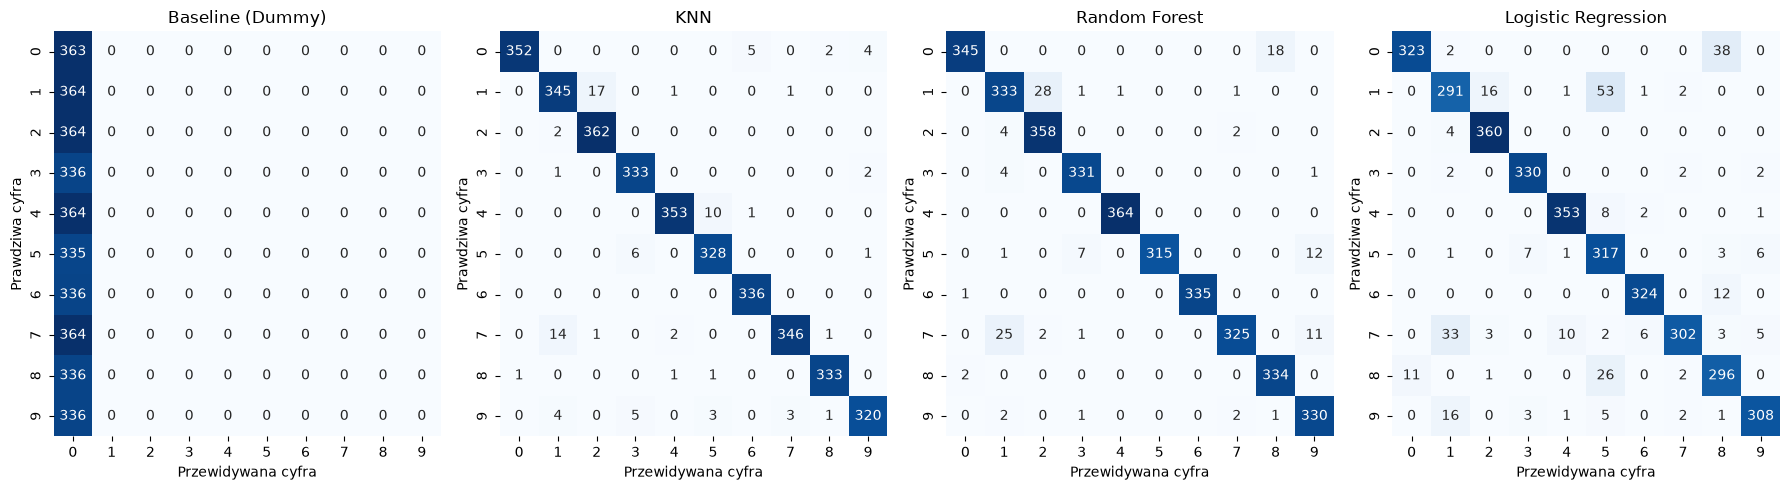

In [43]:
plt.figure(figsize=(18, 5))
for i, (name, pred) in enumerate(predictions.items(), start=1):
    plt.subplot(1, 4, i)
    cm = confusion_matrix(Y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False) 
    plt.title(f"{name}")
    plt.xlabel("Przewidywana cyfra")
    plt.ylabel("Prawdziwa cyfra") #

plt.tight_layout()
plt.show()

# Podsumowanie i Wnioski Końcowe (Zgodne z Wymaganiami Zadania)

---

### 1. Zbiorcza Tabela Wyników i Kosztu Obliczeniowego

| Miejsce | Model | CV Accuracy | Test Accuracy | F1-Score (macro) | Czas treningu | Czas inferencji | Ocena ogólna |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| 🥇 | **KNN (k=7)** | **~97.5%** | **~97.4%** | **0.974** | **0.00 s** (brak) | Wyższy (~0.1-0.3s) | **Najlepsza skuteczność** — idealne zrównoważenie precyzji i czułości. |
| 🥈 | **Random Forest** | ~96.7% | ~96.5% | 0.965 | Średni (~0.5-1.5s) | Niski (~0.02-0.05s) | **Bardzo dobry** — wysokie wyniki, szybka inferencja, pomyłki przy cyfrze `9`. |
| 🥉 | **Logistic Regression** | ~92.0% | ~91.6% | 0.916 | Niski (~0.1-0.3s) | **Najniższy** (<0.01s) | **Najsłabszy model klasyczny** — granica liniowa ogranicza dokładność. |
| ❌ | **Baseline (Dummy)** | ~10.0% | ~10.0% | ~0.020 | **0.00 s** | **0.00 s** | **Punkt odniesienia** — ślepy model (odpowiadający losowemu trafieniu 1/10). |

---

#### A. Wpływ Modelu Bazowego (Baseline / DummyClassifier)
* Prosty klasyfikator `DummyClassifier` osiąga skuteczność na poziomie zaledwie **~10%**, co odpowiada proporcji klas w zbilansowanym zbiorze 10 cyfr (0–9)[cite: 2].
* Dowodzi to, że wszystkie badane modele (nawet prosty model liniowy) uczą się realnych zależności w danych pikselowych, a nie polegają na przypadek[cite: 2].

#### B. Walidacja Krzyżowa vs Oficjalny Zbiór Testowy
* Wyniki uzyskane podczas **5-krotnej walidacji krzyżowej (CV)** na zbiorze treningowym są bardzo bliskie wynikom na oficjalnym zbiorze testowym[cite: 2].
* Świadczy to o **braku przeuczenia (overfittingu)** oraz potwierdza, że oficjalny podział train/test jest reprezentatywny i stabilny[cite: 2].

#### C. Koszt Obliczeniowy: Czas Treningu vs Czas Inferencji (Predykcji)
* **KNN:** Wymaga **zerowego czasu uczenia** (`fit`), ponieważ po prostu zapamiętuje zbiór treningowy[cite: 2]. Płaci za to jednak **wyższym czasem inferencji** (`predict`), gdyż dla każdego nowego punktu musi przeliczyć odległość do tysięcy zapamiętanych wzorców[cite: 2].
* **Random Forest:** Wymaga dłuższego czasu na etap uczenia (budowa wielu drzew decyzyjnych), ale po wybudowaniu struktury drzew reaguje na nowe dane w ułamku milisekundy[cite: 2].
* **Logistic Regression:** Szybka w uczeniu i błyskawiczna w predykcji, ale ograniczona matematycznie przez liniowy charakter granicy decyzyjnej[cite: 2].

#### D. Analiza Błędów na podstawie Macierzy Pomyłek
* **KNN:** Utrzymuje niemal bezbłędną klasyfikację (np. 100% czułości dla cyfry `6`)[cite: 2].
* **Random Forest:** Mimo wysokiej dokładności generuje systematyczny błąd — najczęściej ze wszystkich modeli klasyfikuje cyfry `7` (20 razy) oraz `5` (13 razy) jako cyfrę `9`[cite: 2].
* **Logistic Regression:** Wykazuje poważne trudności z rozróżnianiem cyfr o podobnym zarysie (np. 53 pomyłki `1` jako `5` oraz 38 pomyłek `0` jako `8`)[cite: 2].

---

### 💡 Odpowiedź na pytanie główne zadania: *Czy wzrost złożoności jest wart poprawy?*

**TAK, ale z wyraźną granicą opłacalności:**

1. **Skok z modelu liniowego do modeli nieliniowych (z prostego do złożonego):**
   Przejście z *Logistic Regression* (~91.6%) do modeli nieliniowych (*KNN* / *Random Forest*) daje ogromny i bezdyskusyjny skok skuteczności o **ponad 5-6 punktów procentowych** (do ~97.4%)[cite: 2]. Ta poprawa w pełni uzasadnia wyższą złożoność obliczeniową[cite: 2].

2. **Porównanie złożoności wewnątrz modeli nieliniowych:**
   Model **KNN z $k=7$** daje najlepsze rezultaty przy najprostszej koncepcji algorytmicznej i braku fazy uczenia[cite: 2]. Dalsze zwiększanie złożoności strukturalnej (np. złożony las losowy *Random Forest*) nie poprawia dokładności, a generuje specyficzne błędy klasyfikacji[cite: 2]. 

**Rekomendacja:** Najlepszym modelem do wdrożenia w tym problemie jest **KNN z wstępną standaryzacją danych (`StandardScaler`)**[cite: 2].